In [46]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 
import tol_colors as tc

import tools
import my_plot as mplt

In [47]:
theta_bar = 1.7*1e-6

In [48]:
plt.rcParams['font.size']=14
colors = mplt.set_colors(4, palette="colorblind")
colors2 = tc.colorsets['vibrant']

In [49]:
def extract_PS_ynmax(folder_path, ellmax, ymax, zcon):
    """Extract power spectra from the output of the FH code. """
    folder = Path(folder_path) / "FH" / "yn_T_aniso_system" 
    file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_nmax_{zcon}.dat"))
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_zcon_{zcon}.dat"))
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}.dat"))

    ell = []
    TT = []
    muT = []
    yT = []
    deltaTT = []
    EE = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    TT = np.loadtxt(file_path, comments='#')[:, 1]
    deltaTT = np.loadtxt(file_path, comments='#')[:, 3]
    muT = np.loadtxt(file_path, comments='#')[:, 4]
    yT = np.loadtxt(file_path, comments='#')[:, 5]
    EE = np.loadtxt(file_path, comments='#')[:, 6]

    return np.array(ell), np.array(TT), np.array(EE), np.array(yT), np.array(muT), np.array(deltaTT)

In [50]:
def extract_PS(folder_path, ellmax, ymax, zcon):
    """Extract power spectra from the output of the FH code. """
    folder = Path(folder_path) / "FH" / "yn_T_aniso_system" 
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_nmax_{zcon}.dat"))
    file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_zcon_{zcon}.dat"))
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}.dat"))

    ell = []
    TT = []
    muT = []
    yT = []
    deltaTT = []
    EE = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    TT = np.loadtxt(file_path, comments='#')[:, 1]
    deltaTT = np.loadtxt(file_path, comments='#')[:, 3]
    muT = np.loadtxt(file_path, comments='#')[:, 4]
    yT = np.loadtxt(file_path, comments='#')[:, 5]
    EE = np.loadtxt(file_path, comments='#')[:, 6]

    return np.array(ell), np.array(TT), np.array(EE), np.array(yT), np.array(muT), np.array(deltaTT)

In [51]:
def extract_PS2(folder_path, ellmax, ymax):
    """Extract power spectra from the output of the FH code. """
    folder = Path(folder_path) / "FH" / "yn_T_aniso_system" 
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_nmax_{zcon}.dat"))
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_zcon_{zcon}.dat"))
    file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic.dat"))

    ell = []
    TT = []
    muT = []
    yT = []
    deltaTT = []
    EE = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    TT = np.loadtxt(file_path, comments='#')[:, 1]
    deltaTT = np.loadtxt(file_path, comments='#')[:, 3]
    muT = np.loadtxt(file_path, comments='#')[:, 4]
    yT = np.loadtxt(file_path, comments='#')[:, 5]
    EE = np.loadtxt(file_path, comments='#')[:, 6]

    return np.array(ell), np.array(TT), np.array(EE), np.array(yT), np.array(muT), np.array(deltaTT)

In [52]:
ell, TT, EE, yT_5, muT_5, deltaTT_5 = extract_PS_ynmax("../Data/Dark-photons/outputs_dp_PS-ynmax/batch/",15,5,"001")
_ , _ , _ , yT_9, muT_9, deltaTT_9 = extract_PS_ynmax("../Data/Dark-photons/outputs_dp_PS-ynmax/batch/",15,9,"002")
_ , _ , _ , yT_13, muT_13, deltaTT_13 = extract_PS_ynmax("../Data/Dark-photons/outputs_dp_PS-ynmax/batch/",15,13,"003")
_ , _ , _ , yT_15, muT_15, deltaTT_15 = extract_PS_ynmax("../Data/Dark-photons/outputs_dp_PS-ynmax/batch/",15,15,"004")

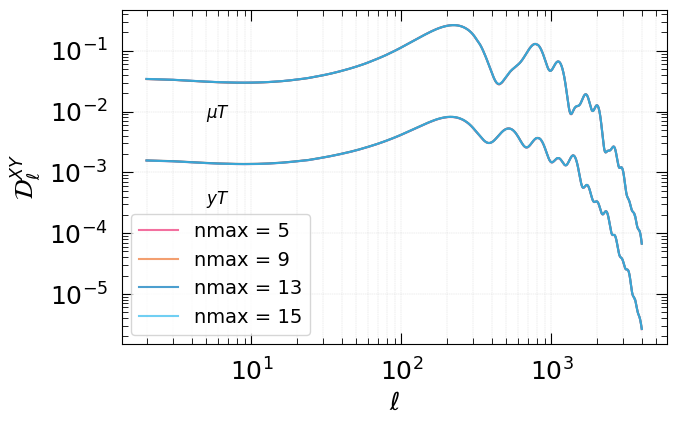

In [53]:
# Plot to test if nmax makes a difference in the power spectra.
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))


ax.plot(ell, muT_5, color=colors2[3], alpha=0.7, linestyle="-", label="nmax = 5")
ax.plot(ell, muT_9, color=colors2[0], alpha=0.7, linestyle="-", label="nmax = 9")
ax.plot(ell, muT_13, color=colors2[1], alpha=0.7, linestyle="-", label="nmax = 13")
ax.plot(ell, muT_15, color=colors2[2], alpha=0.7, linestyle="-", label="nmax = 15")

ax.plot(ell, yT_5, color=colors2[3], alpha=0.7, linestyle="-")
ax.plot(ell, yT_9, color=colors2[0], alpha=0.7, linestyle="-")
ax.plot(ell, yT_13, color=colors2[1], alpha=0.7, linestyle="-")
ax.plot(ell, yT_15, color=colors2[2], alpha=0.7, linestyle="-")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{XY}} $", y_log=True, title=None)

ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
ax.annotate("$\\mu T$", xy=(5, 8e-3), fontsize=12)



ax.legend()
plt.show()

In [64]:
ell, TT, _ , yT, muT, deltaTT = extract_PS2("../Data/Dark-photons/outputs-dp1.0_PS-testlogdens2/",5,15)
_ , _ , _ , yT_1, muT_1, deltaTT_1 = extract_PS2("../Data/Dark-photons/outputs-dp1.1_PS-testlogdens2/",5,15)

ell, TT0, _ , yT0, muT0, deltaTT0 = extract_PS("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"001")
_ , _ , _ , yT0_1, muT0_1, deltaTT0_1 = extract_PS("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"002")

/var/folders/w4/tjml0h7x6sbf6bmxnl05s_z40000gp/T/ipykernel_6031/3365189863.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


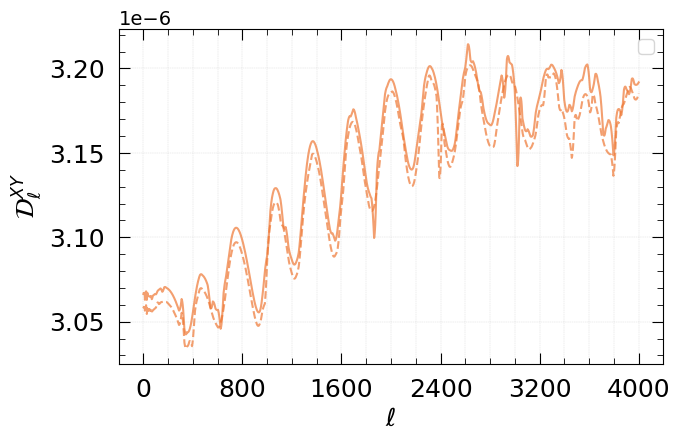

In [69]:
# Plot to test if nmax makes a difference in the power spectra.
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))


# ax.plot(ell, muT/TT, color=colors2[3], alpha=0.7, linestyle="-", label="zcon = 5e6")
# ax.plot(ell, muT_1/TT, color=colors2[0], alpha=0.7, linestyle="-", label="zcon = 5e5")

# ax.plot(ell, muT0/TT0, color=colors2[3], alpha=0.7, linestyle="-", label="zcon = 5e6")
# ax.plot(ell, muT0_1/TT0, color=colors2[0], alpha=0.7, linestyle="--", label="zcon = 5e5")

# ax.plot(ell, yT/TT, color=colors2[3], alpha=0.7, linestyle="-")
ax.plot(ell, yT_1/TT, color=colors2[0], alpha=0.7, linestyle="-")



# ax.plot(ell, yT0/TT0, color=colors2[3], alpha=0.7, linestyle="--")
ax.plot(ell, yT0_1/TT0, color=colors2[0], alpha=0.7, linestyle="--")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{XY}} $", y_log=False, title=None)

ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
ax.annotate("$\\mu T$", xy=(5, 8e-3), fontsize=12)



ax.legend()
plt.show()

/var/folders/w4/tjml0h7x6sbf6bmxnl05s_z40000gp/T/ipykernel_6031/2891633739.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


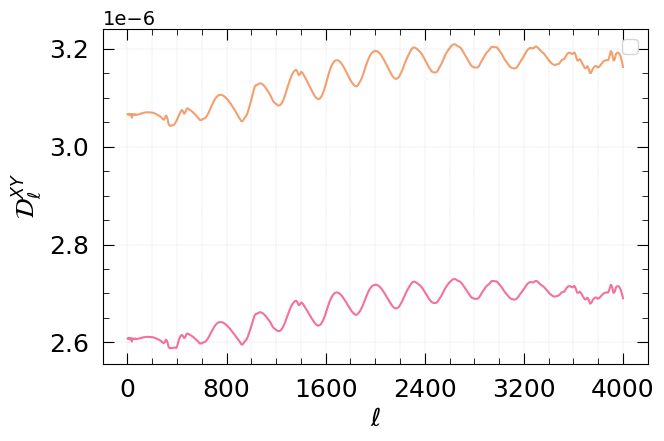

In [ ]:
# Plot to test if nmax makes a difference in the power spectra.
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))


# ax.plot(ell, muT/TT, color=colors2[3], alpha=0.7, linestyle="-", label="zcon = 5e6")
# ax.plot(ell, muT_1/TT, color=colors2[0], alpha=0.7, linestyle="-", label="zcon = 5e5")


ax.plot(ell, yT/TT, color=colors2[3], alpha=0.7, linestyle="-")
ax.plot(ell, yT_1/TT, color=colors2[0], alpha=0.7, linestyle="-")



mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{XY}} $", y_log=False, title=None)

ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
ax.annotate("$\\mu T$", xy=(5, 8e-3), fontsize=12)



ax.legend()
plt.show()